In [5]:
from MMAS_adaptado import *

## Definimos los parámetros fijos y los rangos de los hiperparámetros que buscamos optimizar

En MMAS solo deposita feromona la mejor hormiga y la feromona queda acotada entre tau_min y tau_max. Además de alpha, beta y rho, buscaremos el valor óptimo de los parámetros propios de MMAS: qué hormiga deposita (la mejor global o la mejor de cada iteración) y el factor que fija tau_min. Q se deja fijo en 1, ya que tau_max se calcula a partir de la mejor distancia y con el recorte al rango [tau_min, tau_max] Q deja de influir.

In [6]:
N = 30
T = 200
alpha = (np.linspace(1, 1.5, 5))
beta = (np.linspace(0.5, 5, 5))
rho = (np.linspace(0.02, 0.5, 5))
Q = 1
usar_mejor_global = (True, False)
factor_tau_min = (2, 5, 10)

cerrado = True
random_state = (123, 1234, 12345)
inicio = 13

file_path = "data/matriz_distancias.csv"
dist_matrix = LoadDistanceMatrix(file_path)

print(alpha)
print(beta)
print(rho)

[1.    1.125 1.25  1.375 1.5  ]
[0.5   1.625 2.75  3.875 5.   ]
[0.02 0.14 0.26 0.38 0.5 ]


## Realizamos la búsqueda en rejilla (grid search)

In [7]:
def ejecuta_config(N, T, alpha, beta, rho, Q, cerrado, random_state, inicio, dist_matrix, mejor_global, factor):
    best_outputs, best_outputs_global, best_ant_f, best_ant_x = AntColonySystem(N, T, alpha, beta, rho, Q, dist_matrix, cerrado, random_state, inicio,
                                                                                usar_mejor_global=mejor_global, factor_tau_min=factor, mostrar=False)
    return {'options': (alpha, beta, rho, mejor_global, factor),
            'semilla': random_state,
            'outputs': best_outputs,
            'outputs_global': best_outputs_global,
            'fitness': best_ant_f,
            'solution': best_ant_x.copy()}

In [8]:
import itertools
import pandas as pd
from joblib import Parallel, delayed

combinaciones = list(itertools.product(alpha, beta, rho, usar_mejor_global, factor_tau_min, random_state))

resultados = Parallel(n_jobs=-1, verbose=10)(
    delayed(ejecuta_config)(N, T, a, b, r, Q, cerrado, s, inicio, dist_matrix, mg, fm)
    for a, b, r, mg, fm, s in combinaciones)

filas = []
for res in resultados:
    a, b, r, mg, fm = res['options']
    filas.append({"alpha": a,
                  "beta": b,
                  "rho": r,
                  "mejor_global": mg,
                  "factor_tau_min": fm,
                  "semilla": res['semilla'],
                  "fitness": res['fitness'],
                  "solution": res['solution']})

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done   9 tasks      | elapsed:   22.6s
[Parallel(n_jobs=-1)]: Done  18 tasks      | elapsed:   38.7s
[Parallel(n_jobs=-1)]: Done  29 tasks      | elapsed:   41.2s
[Parallel(n_jobs=-1)]: Done  40 tasks      | elapsed:   56.9s
[Parallel(n_jobs=-1)]: Done  53 tasks      | elapsed:  1.2min
[Parallel(n_jobs=-1)]: Done  66 tasks      | elapsed:  1.5min
[Parallel(n_jobs=-1)]: Done  81 tasks      | elapsed:  1.8min
[Parallel(n_jobs=-1)]: Done  96 tasks      | elapsed:  1.9min
[Parallel(n_jobs=-1)]: Done 113 tasks      | elapsed:  2.3min
[Parallel(n_jobs=-1)]: Done 130 tasks      | elapsed:  2.6min
[Parallel(n_jobs=-1)]: Done 149 tasks      | elapsed:  3.0min
[Parallel(n_jobs=-1)]: Done 168 tasks      | elapsed:  3.3min
[Parallel(n_jobs=-1)]: Done 189 tasks      | elapsed:  3.6min
[Parallel(n_jobs=-1)]: Done 210 tasks      | elapsed:  4.1min
[Parallel(n_jobs=-1)]: Done 233 tasks      | elapsed:  

## Analisis de resultados

In [9]:
df = pd.DataFrame(filas)
df["solution"] = df["solution"].apply(list)

df.to_pickle("resultados_grid_mmas.pkl")
df.drop(columns="solution").to_csv("resultados_grid_mmas.csv", index=False)

resumen = (df.groupby(["alpha", "beta", "rho", "mejor_global", "factor_tau_min"])["fitness"]
             .agg(["mean", "std", "min"])
             .sort_values("mean")
             .reset_index())

resumen.head(10)

,alpha,beta,rho,mejor_global,factor_tau_min,mean,std,min
0,1.375,5.000,0.02,True,10,17759.936141,133.154839,17623.554927
1,1.375,5.000,0.02,True,2,17759.936141,133.154839,17623.554927
2,1.375,5.000,0.02,True,5,17759.936141,133.154839,17623.554927
3,1.000,3.875,0.14,True,2,17826.509763,275.067378,17591.788864
4,1.000,5.000,0.38,True,2,17842.113000,109.061090,17734.876261
5,1.000,3.875,0.26,False,5,17859.136015,52.668669,17828.523083
6,1.125,5.000,0.38,True,2,17903.203527,321.476149,17539.148181
7,1.375,3.875,0.26,False,2,17915.598354,142.273508,17830.743878
8,1.375,3.875,0.14,True,2,17916.842561,355.331261,17514.341562
9,1.000,3.875,0.50,False,2,17932.242473,47.886729,17891.414432


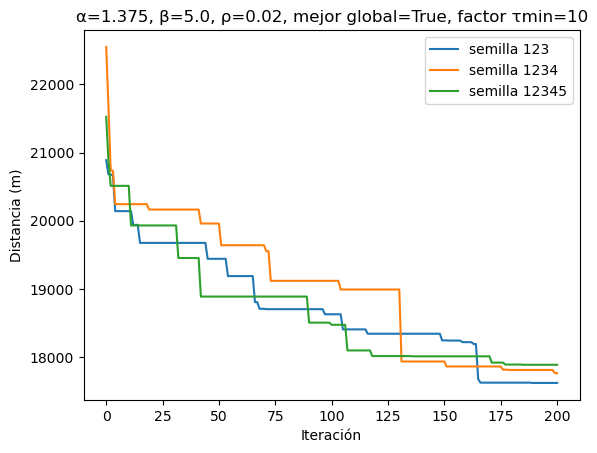

In [10]:
mejor = resumen.iloc[0]
for res in resultados:
    if res['options'] == (mejor.alpha, mejor.beta, mejor.rho, mejor.mejor_global, mejor.factor_tau_min):
        plt.plot(res['outputs_global'], label=f"semilla {res['semilla']}")
plt.xlabel("Iteración"); plt.ylabel("Distancia (m)")
plt.title(f"α={mejor.alpha}, β={mejor.beta}, ρ={mejor.rho}, mejor global={mejor.mejor_global}, factor τmin={mejor.factor_tau_min}")
plt.legend(); plt.show()